# 02 · Choosing what to study

A session shows **at most N unique words**, drawn so that the words you are worst at come
up most often. This notebook shows what that draw actually does.

Covers `flashcards/session.py`: filtering (`mode`), ordering, the session cap (`limit`),
and the adaptive repeat picker.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "experiments")]

import matplotlib.pyplot as plt
import pandas as pd
from demo_workbook import make_demo_workbook
from flashcards.workbook import load_cards

WORKBOOK = make_demo_workbook(ROOT / "experiments" / "_demo" / "demo_vocab.xlsx")
cards = load_cards(str(WORKBOOK)).cards
print(f"{len(cards)} words in the demo library")

48 words in the demo library


## 1. Filtering: what is even in scope

Three modes, all pure functions over the card list.

| mode | what it selects |
|---|---|
| `mix` | every topic |
| `topic` | only the sheets you tick |
| `difficult` | only words at or below a threshold — **ungraded words excluded**, since there is no score to be "difficult" yet |

In [2]:
from flashcards.session import build_deck

scope = {
    "mix": build_deck(cards, mode="mix", seed=0),
    "topic=Verbs,Household": build_deck(cards, mode="topic", topics=["Verbs", "Household"], seed=0),
    "difficult <=2": build_deck(cards, mode="difficult", difficult_threshold=2, seed=0),
    "difficult <=3": build_deck(cards, mode="difficult", difficult_threshold=3, seed=0),
}
pd.DataFrame([{"mode": k, "words in scope": len(v)} for k, v in scope.items()])

,mode,words in scope
0,mix,48
1,"topic=Verbs,Household",16
2,difficult <=2,17
3,difficult <=3,26


In [3]:
# Ungraded words are in "mix" but never in "difficult" -- worth seeing explicitly.
ungraded = {c.id for c in cards if c.confidence is None}
print(f"ungraded words in the library : {len(ungraded)}")
print(f"  ... of them in mix          : {len(ungraded & {c.id for c in scope['mix']})}")
print(f"  ... of them in difficult<=2 : {len(ungraded & {c.id for c in scope['difficult <=2']})}")

ungraded words in the library : 5
  ... of them in mix          : 5
  ... of them in difficult<=2 : 0


## 2. The weighting

Inside the scope, every word gets a **draw weight** that falls as its score rises:

```
weight(score) = (5.5 - score) ** 2      ungraded -> (5.5) ** 2
```

So a word at 1 is 81x likelier to be drawn than one at 5, and a word you have never seen
outranks both.

In [4]:
from flashcards.session import WEIGHT_EXPONENT, selection_weight

w = pd.DataFrame([{"score": s, "weight": selection_weight(s),
                   "relative to a 5": selection_weight(s) / selection_weight(5.0)}
                  for s in [None, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]])
w["score"] = w["score"].fillna("ungraded")
w.round(2)

,score,weight,relative to a 5
0,ungraded,30.25,121.0
1,1.0,20.25,81.0
2,1.5,16.00,64.0
3,2.0,12.25,49.0
4,2.5,9.00,36.0
5,3.0,6.25,25.0
6,3.5,4.00,16.0
7,4.0,2.25,9.0
8,4.5,1.00,4.0
9,5.0,0.25,1.0


### Why squared, and not simply `5.5 - score`

Because the *count* of strong words otherwise wins. In a mature library most words are
already at 4 or 5; there are simply far more of them. A linear weight lets that mass
drown out the handful of weak words you actually need to drill.

The exponent is a named constant in `session.py`, so you can sharpen or soften it.

In [5]:
# Same library, same deck size, only the exponent differs.
def weak_share(exponent: float, trials: int = 300, size: int = 10) -> float:
    import flashcards.session as S
    old, S.WEIGHT_EXPONENT = S.WEIGHT_EXPONENT, exponent
    try:
        weak = total = 0
        for seed in range(trials):
            for c in build_deck(cards, mode="mix", order="weighted", limit=size, seed=seed):
                total += 1
                weak += (c.confidence is None or c.confidence <= 2)
        return 100 * weak / total
    finally:
        S.WEIGHT_EXPONENT = old

share = pd.DataFrame([
    {"exponent": f"{e}" + (" (in use)" if e == WEIGHT_EXPONENT else ""),
     "% of deck at score <=2 or ungraded": round(weak_share(e), 1)}
    for e in (0.0, 1.0, 2.0, 3.0)
])
share

,exponent,% of deck at score <=2 or ungraded
0,0.0,45.5
1,1.0,69.2
2,2.0 (in use),82.6
3,3.0,90.7


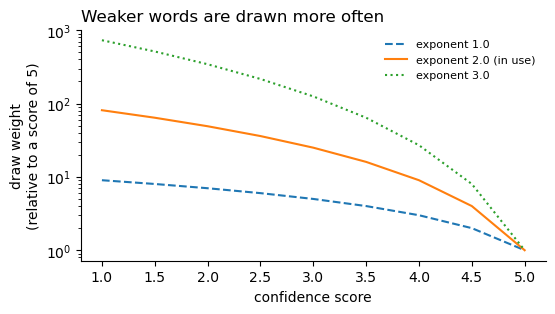

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
scores = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
for e, style in [(1.0, "--"), (2.0, "-"), (3.0, ":")]:
    vals = [(5.5 - s) ** e for s in scores]
    ax.plot(scores, [v / vals[-1] for v in vals], style,
            label=f"exponent {e}" + (" (in use)" if e == WEIGHT_EXPONENT else ""))
ax.set_yscale("log"); ax.set_xlabel("confidence score")
ax.set_ylabel("draw weight\n(relative to a score of 5)")
ax.set_title("Weaker words are drawn more often", loc="left")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)

## 3. The session cap

`limit` caps the deck at that many **unique** words. It is applied after ordering, and for
the weighted order that truncation *is* the weighted sample — the ordering keys do both
jobs in one pass.

No word can appear twice in one deck.

In [7]:
deck = build_deck(cards, mode="mix", order="weighted", limit=10, seed=42)
print(f"library {len(cards)} -> deck {len(deck)}, unique {len({c.id for c in deck})}")
pd.DataFrame([{"#": i, "word": c.term, "topic": c.topic, "score": c.confidence}
              for i, c in enumerate(deck, 1)])

library 48 -> deck 10, unique 10


,#,word,topic,score
0,1,ausfuehrlich,Adjectives & Adverbs,NaN
1,2,Haltestelle,Travel & Transport,1.0
2,3,Flugzeug,Travel & Transport,NaN
3,4,zuverlaessig,Adjectives & Adverbs,4.0
4,5,Gepaeck,Travel & Transport,2.0
5,6,Schreibtisch,School & Office,1.0
6,7,knapp,Adjectives & Adverbs,1.0
7,8,allmaehlich,Adjectives & Adverbs,3.0
8,9,Unterlagen,School & Office,2.0
9,10,vermeiden,Verbs,3.0


## 4. What the draw looks like over many sessions

One deck is a single random draw, so judge the bias over many. Below: 500 decks of 10,
drawn from the same 48-word library, grouped by score.

In [8]:
from collections import Counter

TRIALS, SIZE = 500, 10
lib = Counter(c.confidence for c in cards)
drawn = Counter()
for seed in range(TRIALS):
    for c in build_deck(cards, mode="mix", order="weighted", limit=SIZE, seed=seed):
        drawn[c.confidence] += 1

keys = sorted(lib, key=lambda v: (v is not None, v))
tab = pd.DataFrame([{
    "score": "ungraded" if k is None else k,
    "% of library": 100 * lib[k] / len(cards),
    "% of decks drawn": 100 * drawn[k] / (TRIALS * SIZE),
} for k in keys])
tab["over / under"] = (tab["% of decks drawn"] / tab["% of library"]).round(2).astype(str) + "x"
tab.round(1)

,score,% of library,% of decks drawn,over / under
0,ungraded,10.4,26.0,2.49x
1,1.0,20.8,39.3,1.89x
2,2.0,14.6,17.5,1.2x
3,3.0,18.8,12.3,0.66x
4,4.0,16.7,4.4,0.26x
5,5.0,18.8,0.5,0.03x


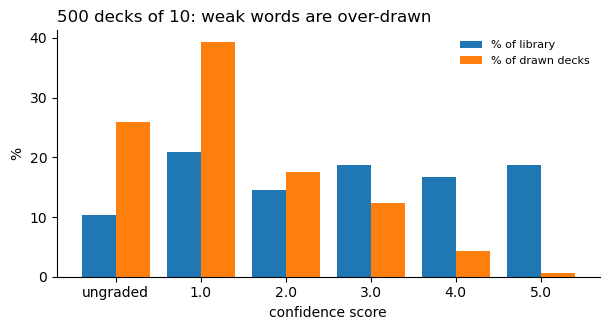

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.2))
x = range(len(tab))
ax.bar([i - 0.2 for i in x], tab["% of library"], width=0.4, label="% of library")
ax.bar([i + 0.2 for i in x], tab["% of decks drawn"], width=0.4, label="% of drawn decks")
ax.set_xticks(list(x)); ax.set_xticklabels(tab["score"])
ax.set_xlabel("confidence score"); ax.set_ylabel("%")
ax.set_title(f"{TRIALS} decks of {SIZE}: weak words are over-drawn", loc="left")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)

Biased, **not exclusive**. Mastered words still surface now and then, which is exactly
what keeps them mastered — a scheme that never revisits a 5 quietly loses it.

In [10]:
mastered_decks = sum(
    any(c.confidence == 5.0 for c in build_deck(cards, mode="mix", order="weighted",
                                                limit=SIZE, seed=seed))
    for seed in range(TRIALS)
)
print(f"decks containing at least one mastered (5.0) word: {mastered_decks}/{TRIALS}")

decks containing at least one mastered (5.0) word: 27/500


## 5. The other orders

`weighted` is the default, but the deterministic orders are still there. Same library,
same cap, four different decks.

In [11]:
from flashcards.session import ORDERS

pd.DataFrame({
    o: [f"{c.term} ({'-' if c.confidence is None else c.confidence})"
        for c in build_deck(cards, mode="mix", order=o, limit=8, seed=42)]
    for o in ORDERS
})

,weighted,lowest_confidence_first,random,oldest_first
0,ausfuehrlich (-),Bericht (-),beitragen (3.0),Schreibtisch (1.0)
1,Haltestelle (1.0),Staubsauger (-),Umstieg (4.0),Muelleimer (2.0)
2,Flugzeug (-),Besprechung (-),werden (5.0),Handtuch (3.0)
3,zuverlaessig (4.0),Flugzeug (-),Staubsauger (-),Geschirr (1.0)
4,Gepaeck (2.0),ausfuehrlich (-),Flugzeug (-),Neugier (3.0)
5,Schreibtisch (1.0),Verspaetung (1.0),Geschirr (1.0),Frist (3.0)
6,knapp (1.0),Geschirr (1.0),ueberlegen (5.0),Erwartung (1.0)
7,allmaehlich (3.0),Gelassenheit (1.0),geeignet (4.0),Termin (1.0)


`lowest_confidence_first` is the strict version: always the 8 weakest, same 8 every
session until you improve them. `weighted` leans the same way but keeps the deck varied,
which is the point — you are not drilling an identical list every day.

## 6. Repeats adapt as you improve

Within a session, words still below 5 come round again. The next one is picked by the same
weighting, but on **live session scores** — so the moment a word improves, its weight drops
and the words that did not improve take over the remaining repeats.

Below: three words, all starting at 1.0. Only `a` improves; watch its share of the next
draws collapse.

In [12]:
from flashcards.session import pick_next_repeat

rows = []
for score_a in (1.0, 2.0, 3.0, 4.0, 4.5):
    scores = {"a": score_a, "b": 1.0, "c": 1.0}
    hits = sum(pick_next_repeat(scores, seed=7, draw=d) == "a" for d in range(600))
    rows.append({"score of 'a'": score_a, "'a' share of next 600 repeats (%)": round(100 * hits / 600, 1)})
pd.DataFrame(rows)

,score of 'a','a' share of next 600 repeats (%)
0,1.0,32.0
1,2.0,22.8
2,3.0,12.8
3,4.0,5.7
4,4.5,1.5


At parity `a` takes its fair third. By the time it reaches 4.5 it is down to a few
percent, and `b` and `c` absorb almost everything.

Two more guarantees, both in `session.pick_next_repeat`:

- the word you just graded is skipped, so nothing is shown twice in a row — unless it is
  the last one left, in which case it is better to show it again than to end the session
  with it still below 5;
- picks are seeded, so a session replays identically for a given seed.

In [13]:
print("just-graded word is skipped :", pick_next_repeat({"a": 1.0, "b": 4.0}, exclude="a", seed=1, draw=1))
print("last word left, shown anyway :", pick_next_repeat({"a": 2.0}, exclude="a", seed=1))
print("nothing left                 :", pick_next_repeat({}, seed=1))

just-graded word is skipped : b
last word left, shown anyway : a
nothing left                 : None


**Next:** [03 · Grading and writing back](03_grading_and_writeback.ipynb) — what a grade
does to a score, a full simulated session, and how the result reaches your .xlsx without
damaging it.